In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [4]:
data = pd.read_csv('House_Pricing_Regression_300_Rows.csv')
data.head()

,House_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Location_Score,Parking_Spaces,Price_NGN
0,1,3824,5,3,34,7,4,845800000
1,2,4157,6,4,21,10,4,896300000
2,3,1510,2,2,23,10,2,375600000
3,4,1944,3,2,16,5,2,433900000
4,5,1780,3,1,9,7,2,379600000


In [5]:
data

,House_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Location_Score,Parking_Spaces,Price_NGN
0,1,3824,5,3,34,7,4,845800000
1,2,4157,6,4,21,10,4,896300000
2,3,1510,2,2,23,10,2,375600000
3,4,1944,3,2,16,5,2,433900000
4,5,1780,3,1,9,7,2,379600000
...,...,...,...,...,...,...,...,...
295,296,852,2,1,26,6,3,235800000
296,297,3905,5,3,37,4,3,789500000
297,298,772,2,2,6,2,1,184900000
298,299,1050,1,1,4,2,1,247800000


In [6]:
data.describe()

,House_ID,Area_sqft,Bedrooms,Bathrooms,Age_years,Location_Score,Parking_Spaces,Price_NGN
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,3.000000e+02
mean,150.500000,2649.990000,3.726667,2.723333,21.033333,5.353333,2.360000,5.676023e+08
std,86.746758,1086.458524,1.572747,1.224112,11.713650,2.891891,1.126037,2.104644e+08
min,1.000000,651.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.687000e+08
25%,75.750000,1741.750000,2.000000,2.000000,11.000000,3.000000,2.000000,3.963500e+08
50%,150.500000,2618.000000,4.000000,3.000000,22.000000,5.000000,2.000000,5.514500e+08
75%,225.250000,3603.000000,5.000000,4.000000,32.000000,8.000000,3.000000,7.537250e+08
max,300.000000,4493.000000,6.000000,5.000000,40.000000,10.000000,4.000000,9.423000e+08


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   House_ID        300 non-null    int64
 1   Area_sqft       300 non-null    int64
 2   Bedrooms        300 non-null    int64
 3   Bathrooms       300 non-null    int64
 4   Age_years       300 non-null    int64
 5   Location_Score  300 non-null    int64
 6   Parking_Spaces  300 non-null    int64
 7   Price_NGN       300 non-null    int64
dtypes: int64(8)
memory usage: 18.9 KB


In [8]:
data.isnull().sum()

House_ID          0
Area_sqft         0
Bedrooms          0
Bathrooms         0
Age_years         0
Location_Score    0
Parking_Spaces    0
Price_NGN         0
dtype: int64

In [9]:
x = data.drop(columns=['House_ID', 'Price_NGN'])
y = data[['Price_NGN']]

In [10]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

In [11]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [12]:
predictions = model.predict(x_test)
print(predictions[5])

[4.2753941e+08]


In [13]:
y_pred = model.predict(x_test)

price = r2_score(y_test, y_pred)
    
print(price)

0.9869892066174407


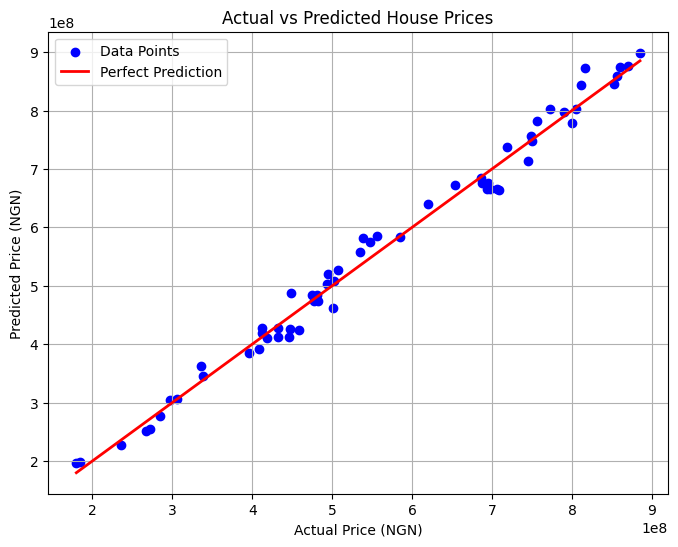

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, color='blue', label='Data Points')

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2,
    label='Perfect Prediction'
)

plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price (NGN)')
plt.ylabel('Predicted Price (NGN)')
plt.legend()
plt.grid(True)
plt.show()